# Projeto completo de Machine Learning — Previsão de cancelamento de reservas de hotéis

**Problema:** classificação binária (`is_canceled`: 1 = reserva cancelada; 0 = não cancelada).  
**Dataset público:** Hotel Booking Demand, disponibilizado também no [TidyTuesday](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-02-11).  
**Modelos:** Regressão Logística e Random Forest.  
**Fluxo:** leitura → EDA → divisão treino/teste → feature engineering → preparação → Boruta (uma vez) → variáveis fixas → modelos → validação → GridSearchCV → teste

> **Decisão metodológica:** o Boruta será executado **uma única vez nos dados de treinamento**. O subconjunto escolhido permanecerá fixo nos dois modelos e em toda a otimização. Não haverá reexecução do Boruta dentro do GridSearchCV. Isso pode deixar os escores de validação cruzada otimistas; o conjunto de teste separado é a avaliação final independente.

## 1. Instalação e importação das bibliotecas
Execute a instalação apenas uma vez. Reinicie o ambiente se o gerenciador de pacotes solicitar.

In [1]:
%pip -q install "scikit-learn>=1.3,<2" "boruta>=0.4.3" pandas numpy matplotlib seaborn joblib requests

In [2]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from boruta import BorutaPy
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
print('Python:', sys.version.split()[0])

Python: 3.13.18


## 2. Leitura dos dados
O arquivo público é baixado diretamente do repositório TidyTuesday. Caso o ambiente não tenha acesso à internet, faça download manual e coloque `hotels.csv` na mesma pasta do notebook.

In [3]:
URL = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv'
try:
    df = pd.read_csv(URL)
except Exception as exc:
    print('Download indisponível; tentando arquivo local:', type(exc).__name__)
    df = pd.read_csv('hotels.csv')
print('Dimensões:', df.shape)
display(df.head())

Dimensões: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
print('Tipos e preenchimento:')
df.info()

Tipos e preenchimento:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64 

In [8]:
display(df.describe(include='all').T.head(25))
assert 'is_canceled' in df.columns, 'A coluna-alvo não foi encontrada.'

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


## 3. Análise exploratória (EDA)
Investigue a distribuição da classe, valores ausentes, diferenças entre hotéis e possíveis padrões de cancelamento. Os gráficos são descritivos, não devem ser usados para ajustar transformações com informações do teste.

In [9]:
display((df.isna().mean().mul(100).sort_values(ascending=False).head(15)).to_frame('% ausente'))
print('Duplicatas exatas:', df.duplicated().sum())

,% ausente
company,94.306893
agent,13.686238
country,0.408744
children,0.003350
arrival_date_month,0.000000
arrival_date_week_number,0.000000
hotel,0.000000
is_canceled,0.000000
stays_in_weekend_nights,0.000000
arrival_date_day_of_month,0.000000


Duplicatas exatas: 31994


In [10]:
print('Distribuição da classe (%):')
display(df['is_canceled'].value_counts(normalize=True).mul(100).round(2))

Distribuição da classe (%):


,proportion
is_canceled,
0,62.96
1,37.04


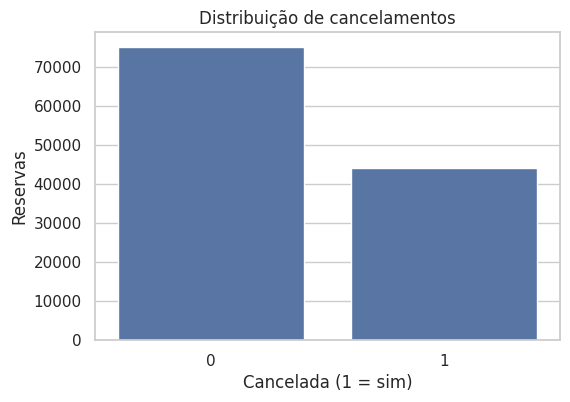

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='is_canceled', ax=ax)
ax.set(title='Distribuição de cancelamentos', xlabel='Cancelada (1 = sim)', ylabel='Reservas')
plt.show()

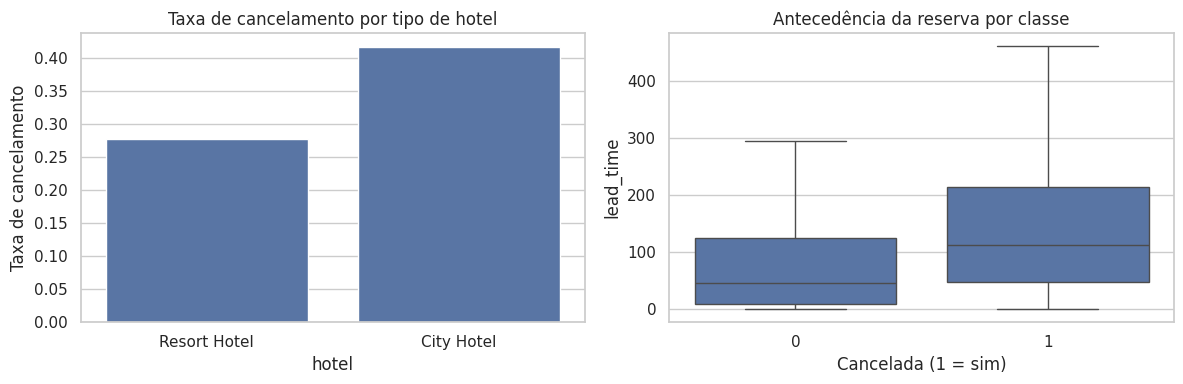

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x='hotel', y='is_canceled', errorbar=None, ax=axes[0])
axes[0].set(title='Taxa de cancelamento por tipo de hotel', ylabel='Taxa de cancelamento')
sns.boxplot(data=df, x='is_canceled', y='lead_time', showfliers=False, ax=axes[1])
axes[1].set(title='Antecedência da reserva por classe', xlabel='Cancelada (1 = sim)')
plt.tight_layout(); plt.show()

## 4. Definição dos atributos e divisão treino/teste

**Prevenção de vazamento temporal:** `reservation_status` e `reservation_status_date` refletem o desfecho da reserva e são removidos. Também retiramos atributos cujo valor pode mudar depois da reserva, como `assigned_room_type`, `booking_changes` e `days_in_waiting_list`, para aproximar o cenário de previsão no instante da reserva. O significado operacional das demais variáveis deve ser confirmado antes de usar o modelo em produção.

**Nota:** este é um exemplo didático com divisão estratificada aleatória. Em produção, uma divisão cronológica seria mais adequada para simular reservas futuras.

In [13]:
COLUNAS_EXCLUIDAS = [
    'is_canceled', 'reservation_status', 'reservation_status_date',
    'assigned_room_type', 'booking_changes', 'days_in_waiting_list'
]
X = df.drop(columns=COLUNAS_EXCLUIDAS, errors='ignore')
y = df['is_canceled'].astype(int)
X_treino_bruto, X_teste_bruto, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('Treino:', X_treino_bruto.shape, '| Teste:', X_teste_bruto.shape)
assert set(X_treino_bruto.index).isdisjoint(set(X_teste_bruto.index))

Treino: (95512, 26) | Teste: (23878, 26)


## 5. Feature Engineering
Criamos atributos que representam a duração da estadia, a composição de hóspedes, o histórico de reservas e a antecedência relativa.

In [14]:
def criar_atributos(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()
    x['total_noites'] = x['stays_in_weekend_nights'].fillna(0) + x['stays_in_week_nights'].fillna(0)
    x['total_hospedes'] = x['adults'].fillna(0) + x['children'].fillna(0) + x['babies'].fillna(0)
    x['possui_criancas'] = ((x['children'].fillna(0) + x['babies'].fillna(0)) > 0).astype(int)
    x['total_reservas_anteriores'] = x['previous_cancellations'].fillna(0) + x['previous_bookings_not_canceled'].fillna(0)
    x['antecedencia_por_noite'] = x['lead_time'].fillna(0) / x['total_noites'].clip(lower=1)
    return x

In [15]:
X_treino_fe = criar_atributos(X_treino_bruto)
X_teste_fe = criar_atributos(X_teste_bruto)
display(X_treino_fe[['total_noites', 'total_hospedes', 'possui_criancas',
                     'total_reservas_anteriores', 'antecedencia_por_noite']].head())

,total_noites,total_hospedes,possui_criancas,total_reservas_anteriores,antecedencia_por_noite
105447,2,1.0,0,0,10.000000
85242,3,2.0,0,0,2.666667
65604,3,2.0,0,0,31.000000
17345,14,2.0,0,0,6.428571
117786,1,1.0,0,0,8.000000


## 6. Pré-processamento
Para valores numéricos: imputação pela mediana e padronização. Para categóricos: imputação pela moda e One-Hot Encoding (`handle_unknown="ignore"`). O pré-processador é **ajustado somente no treino** e depois aplicado ao teste, sem reaprender parâmetros.

A matriz transformada será usada pelo Boruta e pelos dois modelos.

In [16]:
colunas_numericas = X_treino_fe.select_dtypes(include=np.number).columns.tolist()
colunas_categoricas = X_treino_fe.select_dtypes(exclude=np.number).columns.tolist()

preprocessador = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), colunas_numericas),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), colunas_categoricas)
], remainder='drop', sparse_threshold=0)

X_treino_pre = preprocessador.fit_transform(X_treino_fe)
X_teste_pre = preprocessador.transform(X_teste_fe)
nomes_atributos = preprocessador.get_feature_names_out()
print('Atributos antes do Boruta:', len(nomes_atributos))
print('Matrizes:', X_treino_pre.shape, X_teste_pre.shape)

Atributos antes do Boruta: 243
Matrizes: (95512, 243) (23878, 243)


## 7. Seleção de variáveis com Boruta — execução única
O Boruta usa uma Random Forest e atributos embaralhados (*shadow features*) para verificar relevância. Para tornar o exercício viável em sala, usamos uma **amostra estratificada do treino** apenas para a seleção; nenhum dado do teste participa.

As variáveis confirmadas são congeladas. Se nenhuma for confirmada, o notebook interrompe a execução em vez de inventar uma seleção. Os atributos tentativos são exibidos para discussão, mas não entram no subconjunto fixo.

In [20]:
MAX_AMOSTRA_BORUTA = 15000
if len(y_treino) > MAX_AMOSTRA_BORUTA:
    idx_boruta, _ = train_test_split(
        np.arange(len(y_treino)), train_size=MAX_AMOSTRA_BORUTA,
        stratify=y_treino, random_state=RANDOM_STATE
    )
else:
    idx_boruta = np.arange(len(y_treino))

In [21]:
estimador_boruta = RandomForestClassifier(
    n_estimators=120, max_depth=7, class_weight='balanced_subsample',
    n_jobs=-1, random_state=RANDOM_STATE
)
boruta = BorutaPy(
    estimator=estimador_boruta, n_estimators='auto', max_iter=25,
    perc=100, alpha=0.05, random_state=RANDOM_STATE, verbose=0
)
boruta.fit(X_treino_pre[idx_boruta], y_treino.iloc[idx_boruta].to_numpy())
mascara_selecionada = boruta.support_.copy()
atributos_selecionados = nomes_atributos[mascara_selecionada].tolist()
atributos_tentativos = nomes_atributos[boruta.support_weak_].tolist()
assert mascara_selecionada.any(), 'Nenhum atributo confirmado. Revise max_iter ou a estratégia de seleção.'
print('Confirmados:', len(atributos_selecionados))
print('Tentativos:', len(atributos_tentativos))
display(pd.DataFrame({'atributo': nomes_atributos,
                      'ranking_boruta': boruta.ranking_,
                      'selecionado': mascara_selecionada,
                      'tentativo': boruta.support_weak_}).sort_values(['ranking_boruta', 'atributo']).head(50))

Confirmados: 34
Tentativos: 1


,atributo,ranking_boruta,selecionado,tentativo
82,cat__country_DEU,1,True,False
95,cat__country_FRA,1,True,False
98,cat__country_GBR,1,True,False
171,cat__country_PRT,1,True,False
241,cat__customer_type_Transient,1,True,False
242,cat__customer_type_Transient-Party,1,True,False
236,cat__deposit_type_No Deposit,1,True,False
237,cat__deposit_type_Non Refund,1,True,False
222,cat__distribution_channel_Direct,1,True,False
224,cat__distribution_channel_TA/TO,1,True,False


Como Boruta demora um pouco para ser processado, as p´roximas células já trazem os atributos selecionados pelo Boruta

In [17]:
atributos_selecionados = ['num__lead_time',
 'num__arrival_date_year',
 'num__arrival_date_week_number',
 'num__stays_in_weekend_nights',
 'num__stays_in_week_nights',
 'num__adults',
 'num__is_repeated_guest',
 'num__previous_cancellations',
 'num__previous_bookings_not_canceled',
 'num__agent',
 'num__company',
 'num__adr',
 'num__required_car_parking_spaces',
 'num__total_of_special_requests',
 'num__total_noites',
 'num__total_hospedes',
 'num__total_reservas_anteriores',
 'num__antecedencia_por_noite',
 'cat__hotel_City Hotel',
 'cat__hotel_Resort Hotel',
 'cat__country_DEU',
 'cat__country_FRA',
 'cat__country_GBR',
 'cat__country_PRT',
 'cat__market_segment_Direct',
 'cat__market_segment_Groups',
 'cat__market_segment_Offline TA/TO',
 'cat__market_segment_Online TA',
 'cat__distribution_channel_Direct',
 'cat__distribution_channel_TA/TO',
 'cat__deposit_type_No Deposit',
 'cat__deposit_type_Non Refund',
 'cat__customer_type_Transient',
 'cat__customer_type_Transient-Party']

In [18]:
indices_selecionados = [0,
 1,
 2,
 4,
 5,
 6,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 20,
 21,
 22,
 23,
 82,
 95,
 98,
 171,
 216,
 217,
 218,
 219,
 222,
 224,
 236,
 237,
 241,
 242]

In [26]:
# SUBCONJUNTO CONGELADO: será o mesmo para os dois modelos e GridSearchCV.
#indices_selecionados = np.flatnonzero(mascara_selecionada).tolist() Quando o boruta é executado
X_treino_sel = X_treino_pre[:, indices_selecionados]
X_teste_sel = X_teste_pre[:, indices_selecionados]
print('Dimensões após Boruta:', X_treino_sel.shape, X_teste_sel.shape)
print('Lista fixa de atributos:', atributos_selecionados)

Dimensões após Boruta: (95512, 34) (23878, 34)
Lista fixa de atributos: ['num__lead_time', 'num__arrival_date_year', 'num__arrival_date_week_number', 'num__stays_in_weekend_nights', 'num__stays_in_week_nights', 'num__adults', 'num__is_repeated_guest', 'num__previous_cancellations', 'num__previous_bookings_not_canceled', 'num__agent', 'num__company', 'num__adr', 'num__required_car_parking_spaces', 'num__total_of_special_requests', 'num__total_noites', 'num__total_hospedes', 'num__total_reservas_anteriores', 'num__antecedencia_por_noite', 'cat__hotel_City Hotel', 'cat__hotel_Resort Hotel', 'cat__country_DEU', 'cat__country_FRA', 'cat__country_GBR', 'cat__country_PRT', 'cat__market_segment_Direct', 'cat__market_segment_Groups', 'cat__market_segment_Offline TA/TO', 'cat__market_segment_Online TA', 'cat__distribution_channel_Direct', 'cat__distribution_channel_TA/TO', 'cat__deposit_type_No Deposit', 'cat__deposit_type_Non Refund', 'cat__customer_type_Transient', 'cat__customer_type_Transien

## 8. Treinamento inicial e validação cruzada
Comparamos Regressão Logística e Random Forest usando as **mesmas variáveis selecionadas** e a mesma estratégia de validação.

In [27]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
modelos = {
    'Regressão Logística': LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE)
}
resultados_cv = []
for nome, modelo in modelos.items():
    pontuacoes = cross_validate(modelo, X_treino_sel, y_treino, cv=cv,
        scoring={'f1': 'f1', 'precision': 'precision', 'recall': 'recall'},
        n_jobs=1)
    resultados_cv.append({'modelo': nome, **{
        metrica: pontuacoes['test_' + metrica].mean()
        for metrica in ['f1', 'precision', 'recall']}})
df_resultados_cv = pd.DataFrame(resultados_cv).sort_values('f1', ascending=False)
display(df_resultados_cv)

,modelo,f1,precision,recall
1,Random Forest,0.837089,0.867088,0.809124
0,Regressão Logística,0.701246,0.801252,0.623449


## 9. Otimização de hiperparâmetros com GridSearchCV
O conjunto de variáveis é mantido exatamente igual. Executamos uma grade compacta para cada algoritmo, comparando os melhores escores de validação cruzada. Ajuste as grades se houver mais tempo de processamento.

In [28]:
grades = {
    'Regressão Logística': {
        'modelo': LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
        'param_grid': {'C': [0.1, 1.0, 10.0], 'class_weight': [None, 'balanced']}
    },
    'Random Forest': {
        'modelo': RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        'param_grid': {'n_estimators': [100, 200], 'max_depth': [10, None],
                       'min_samples_leaf': [1, 3]}
    }
}
buscas = {}
resumo_otimizacao = []

for nome, configuracao in grades.items():
    busca = GridSearchCV(
        estimator=configuracao['modelo'], param_grid=configuracao['param_grid'],
        scoring='f1', cv=cv, n_jobs=-1, refit=True, verbose=0
    )
    busca.fit(X_treino_sel, y_treino)
    buscas[nome] = busca
    resumo_otimizacao.append({'modelo': nome, 'f1': busca.best_score_,
                              'melhores_parametros': busca.best_params_})
df_otimizacao = pd.DataFrame(resumo_otimizacao).sort_values('f1', ascending=False)
display(df_otimizacao)

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,modelo,f1,melhores_parametros
1,Random Forest,0.837344,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
0,Regressão Logística,0.736859,"{'C': 1.0, 'class_weight': 'balanced'}"


## 10. Escolha do modelo e avaliação final no teste
Escolhemos o melhor algoritmo pelo F1 Score de CV. **Somente agora** usamos o conjunto de teste, uma única vez, para relatar as métricas finais. Não ajuste hiperparâmetros com base nesses resultados.

In [29]:
nome_vencedor = df_otimizacao.iloc[0]['modelo']
modelo_vencedor = buscas[nome_vencedor].best_estimator_
y_pred = modelo_vencedor.predict(X_teste_sel)
y_prob = modelo_vencedor.predict_proba(X_teste_sel)[:, 1]

metricas_teste = {
    'accuracy': accuracy_score(y_teste, y_pred),
    'precision': precision_score(y_teste, y_pred, zero_division=0),
    'recall': recall_score(y_teste, y_pred, zero_division=0),
    'f1': f1_score(y_teste, y_pred, zero_division=0),
}
print('Modelo vencedor:', nome_vencedor)
display(pd.DataFrame([metricas_teste]).round(4))


Modelo vencedor: Random Forest


,accuracy,precision,recall,f1
0,0.8904,0.8756,0.8206,0.8472


In [30]:
print(classification_report(y_teste, y_pred, target_names=['Não cancelada', 'Cancelada']))

               precision    recall  f1-score   support

Não cancelada       0.90      0.93      0.91     15033
    Cancelada       0.88      0.82      0.85      8845

     accuracy                           0.89     23878
    macro avg       0.89      0.88      0.88     23878
 weighted avg       0.89      0.89      0.89     23878




## Exportação do modelo e dos componentes de pré-processamento

Após selecionar o melhor modelo, precisamos salvar os componentes necessários para realizar previsões em novos dados.

Utilizaremos a biblioteca **Joblib** para exportar:

- **Modelo final:** algoritmo treinado e otimizado.
- **Codificadores e transformadores:** responsáveis por preparar novos dados para o modelo.
- **Variáveis selecionadas:** subconjunto definido pelo Boruta, mantendo a mesma estrutura utilizada no treinamento.

Esses componentes serão utilizados posteriormente em uma API, permitindo realizar previsões sem precisar treinar novamente o modelo.


In [31]:
# Reunindo os componentes necessários para a API
artefatos = {
    "modelo": modelo_vencedor,
    "preprocessador": preprocessador,
    "variaveis_selecionadas": atributos_selecionados
}

# Exportando os artefatos em um único arquivo
joblib.dump(artefatos, "modelo_cancelamento_hotel.joblib")

print("Modelo e componentes exportados com sucesso!")

Modelo e componentes exportados com sucesso!


## Estrutura de diretórios da API

hotel-cancellation-api/

│

├── app/

│   ├── __init__.py

│   ├── main.py

│   │

│   ├── api/

│   │   ├── __init__.py

│   │   ├── routes.py

│   │   └── dependencies.py

│   │

│   ├── schemas/

│   │   ├── __init__.py

│   │   └── reservation.py

│   │

│   ├── services/

│   │   ├── __init__.py

│   │   └── prediction_service.py

│   │

│   ├── ml/

│   │   ├── __init__.py

│   │   ├── model_manager.py

│   │   └── feature_engineering.py

│   │

│   └── core/

│       ├── __init__.py

│       └── config.py

│

├── models/

│   └── modelo_cancelamento_hotel.joblib

│

├── tests/

│   ├── test_api.py

│   └── test_prediction.py

│

├── requirements.txt

└── README.md